# Full-forecast backtest: 2020, 2022, 2024

The full forecast, run the way it runs for 2026 but on three past elections, then scored the way a race-rating sheet is: Toss-up / Lean / Likely / Safe, who won each group, which races it missed, and how far off it was in each party's direction.

- **From earlier elections only.**
  - **House:** each year's Stage 1 is fit on 2006 through the election before it, and the H0 error model on the earlier years' residuals (from 2018). Every race is simulated with the race rules (`house.simulation.backtest`, as in `02_monte_carlo.ipynb`).
  - **Senate:** each year's blend centers are out of sample (production weights), with the S-M0 errors fit on earlier years (from 2016), as in `03_monte_carlo.ipynb`. Independent-vs-R races (e.g. Osborn, NE 2024) aren't in the historical panel.
- **Candidate adjustments:** the 2026 points from `data/reference/margin_adjustments_2026.csv`, for MN-05, IA-02, PA-01, NY-18 and UT-02, and Mary Peltola's (AK-SEN) for AK-AL, where she was the Democratic nominee in 2022 and 2024.
  - **Only returning candidates.** An adjustment is about one party's candidate (the file's `party` column), and it applies only when that candidate was on the seat's ballot in an earlier regular November election. A first run has no record for a candidate effect to come from, and special elections don't count. So Peltola is adjusted in 2024 but not 2022.
  - **These are hindsight.** The points were chosen knowing how these races went, so section 5 shows what they do here; it is not an out-of-sample test of them.
- **Same-party top-two races:** the 2026 top-two model (`top_two.py`), with **no polls** (primary 60 / fundraising 40). The 20 California and Washington races come from `data-processing/house/top_two_same_party_history.py`.
- **Kalshi:** 2024 only, since Kalshi listed no race markets before then. Election-eve prices are cached by `src/kalshi/history.py` (no live call here). They are compared with the model, and `run.py`'s toss-up strategy is replayed on them.
- **Errors are political:** actual − forecast margin, D − R. **Positive means Democrats did better than forecast.**

Code: `src/congress/backtest.py`.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from congress import adjustments, report
from congress import backtest as bt
from house import forecast as house_forecast
from kalshi import run as kalshi_run

pd.set_option("display.width", 230)
pd.set_option("display.max_rows", 300)

## Settings

In [2]:
YEARS = [2020, 2022, 2024]
RATING_THRESHOLDS = {"Toss-up": 0.60, "Lean": 0.75, "Likely": 0.95}  # as full_forecast_2026.ipynb

# Candidate adjustments: the 2026 file's points and party, for these races only
ADJUSTED_DISTRICTS = ["MN-05", "IA-02", "PA-01", "NY-18", "UT-02"]
PELTOLA_RACE, PELTOLA_YEARS, PELTOLA_POINTS_FROM = "AK-AL", [2022, 2024], "AK-SEN"  # her House races; her 2026 points
# No adjustment in a candidate's first regular November election for the seat (specials don't count): a candidate
# effect needs a record. The candidate is the one of the adjustment's party (the file's party column)
ONLY_RETURNING_CANDIDATES = True

# Same-party top two: the production settings, no polls
TOP_TWO_WEIGHTS_NO_POLL = house_forecast.TOP_TWO_WEIGHTS_NO_POLL

# Kalshi 2024 replay: run.py's settings
TOSSUP_LOW, TOSSUP_HIGH = kalshi_run.TOSSUP_LOW, kalshi_run.TOSSUP_HIGH
BANKROLL, KELLY_FRACTION, MIN_EDGE = kalshi_run.BANKROLL, kalshi_run.KELLY_FRACTION, kalshi_run.MIN_EDGE
print(report.threshold_line(RATING_THRESHOLDS))

Toss-up < 60% · Lean 60–75% · Likely 75–95% · Safe ≥ 95% (the predicted side's win probability)


In [3]:
template = pd.read_csv(ROOT / "data/reference/full congress track template.csv")
adjustment_file = adjustments.load_margin_adjustments(template=template)
points_2026 = adjustment_file.groupby("race_id")["margin_adjustment"].sum()
party_2026 = adjustment_file.groupby("race_id")["party"].first()
rows = [{"year": y, "race_id": r, "from": r} for y in YEARS for r in ADJUSTED_DISTRICTS]
rows += [{"year": y, "race_id": PELTOLA_RACE, "from": PELTOLA_POINTS_FROM} for y in PELTOLA_YEARS]
candidates = pd.DataFrame(rows)
candidates = candidates.assign(state=candidates["race_id"].str[:2],
                               district=candidates["race_id"].str[3:].replace("AL", "0").astype(int),
                               party=candidates["from"].map(party_2026),
                               margin_adjustment=candidates["from"].map(points_2026))
candidates = bt.returning_candidates(candidates[["year", "state", "district", "race_id", "party", "margin_adjustment"]])
assert candidates.loc[candidates["race_id"] == PELTOLA_RACE, "candidate"].str.contains("Peltola").all()
candidates["applied"] = candidates["returning"] | (not ONLY_RETURNING_CANDIDATES)
BACKTEST_ADJUSTMENTS = candidates[candidates["applied"]].reset_index(drop=True)

house_inputs = bt.load_house_inputs()
display(Markdown(f"**{len(BACKTEST_ADJUSTMENTS)} of {len(candidates)} race-years adjusted**; the rest are the "
                 "candidate's first regular November election for the seat"))
candidates

**11 of 17 race-years adjusted**; the rest are the candidate's first regular November election for the seat

,year,state,district,race_id,party,margin_adjustment,candidate,earlier_runs,returning,applied
0,2020,MN,5,MN-05,D,-6.0,Ilhan Omar,2018,True,True
1,2020,IA,2,IA-02,R,2.5,Mariannette Miller-Meeks,"2008, 2010, 2014",True,True
2,2020,PA,1,PA-01,R,-5.0,Brian K Fitzpatrick,2018,True,True
3,2020,NY,18,NY-18,R,-2.5,Chele C Farley,,False,False
4,2020,UT,2,UT-02,R,-2.5,Chris Stewart,"2012, 2014, 2016, 2018",True,True
5,2022,MN,5,MN-05,D,-6.0,Ilhan Omar,"2018, 2020",True,True
6,2022,IA,2,IA-02,R,2.5,Ashley Hinson,,False,False
7,2022,PA,1,PA-01,R,-5.0,Brian K Fitzpatrick,"2018, 2020",True,True
8,2022,NY,18,NY-18,R,-2.5,Colin J Schmitt,,False,False
9,2022,UT,2,UT-02,R,-2.5,Chris Stewart,"2012, 2014, 2016, 2018, 2020",True,True


## The backtests

Two House runs from the same draws: the **model** (no adjustments) and **adjusted** (the adjustments above). The Senate has no adjustment in these years, since Peltola ran for the House. Everything below uses the adjusted run unless it says otherwise.

In [4]:
adjust_by = BACKTEST_ADJUSTMENTS[["year", "state", "district", "margin_adjustment"]]
house_model = bt.house_backtest(house_inputs, years=YEARS)
house_adjusted = bt.house_backtest(house_inputs, adjustments=adjust_by, years=YEARS)
senate = bt.senate_races(years=YEARS, thresholds=RATING_THRESHOLDS)

races_model = pd.concat([bt.house_races(house_model, house_inputs, None, RATING_THRESHOLDS), senate], ignore_index=True)
races = pd.concat([bt.house_races(house_adjusted, house_inputs, adjust_by, RATING_THRESHOLDS), senate],
                  ignore_index=True)
display(races.groupby(["chamber", "year"]).size().rename("races").unstack("year"))

year,2020,2022,2024
chamber,,,
House,435,435,435
Senate,34,33,33


## 1. Scorecard

For each chamber and year:
- **Calls and misses** over every race with a known winner. The House counts all 435, including races decided by rule.
- **Brier score** on P(D).
- **D wins:** expected (the sum of P(D)), called (races the model favored a Democrat in), and actual.
- **Margin errors** over the simulated races, all of them and then only those not rated Safe. Bias is actual − forecast: positive means Democrats did better than forecast.

The Senate rows count only the races in the historical panel, not the chamber.

In [5]:
bt.scorecard(races).T.round(3)

chamber                  House                    Senate                     House   Senate
year                      2020     2022     2024    2020    2022    2024    pooled   pooled
races                  435.000  435.000  435.000  34.000  33.000  33.000  1305.000  100.000
called right           422.000  418.000  428.000  32.000  30.000  32.000  1268.000   94.000
accuracy                 0.970    0.961    0.984   0.941   0.909   0.970     0.972    0.940
misses                  13.000   17.000    7.000   2.000   3.000   1.000    37.000    6.000
not Safe                75.000   69.000   62.000  15.000  12.000   8.000   206.000   35.000
misses among not Safe    9.000   15.000    7.000   2.000   3.000   1.000    31.000    6.000
Brier                    0.028    0.029    0.014   0.055   0.039   0.031     0.024    0.042
expected D wins        232.761  209.909  217.230  15.781  13.199  18.863   659.900   47.843
called D wins          233.000  212.000  218.000  15.000  12.000  20.000   663.000   47.000
actual D wins          222.000  213.000  215.000  13.000  15.000  19.000   650.000   47.000
all: margin n          408.000  399.000  398.000  34.000  33.000  33.000  1205.000  100.000
all: MAE                 4.761    5.143    4.311   5.127   4.280   4.062     4.739    4.496
all: RMSE                6.357    6.255    5.873   6.738   5.664   4.985     6.167    5.850
all: bias (D+)          -3.080    1.621   -1.440  -4.340   0.876  -2.274    -0.982   -1.937
not Safe: margin n      75.000   69.000   62.000  15.000  12.000   8.000   206.000   35.000
not Safe: MAE            3.842    4.820    3.855   3.812   3.540   2.265     4.173    3.365
not Safe: RMSE           4.809    5.836    5.739   5.332   4.007   3.108     5.454    4.461
not Safe: bias (D+)     -1.912    0.833   -1.565  -3.782   2.113  -2.256    -0.888   -1.412

In [6]:
# The House: the simulated seats against what happened
bt.house_seats(house_adjusted)

,median D seats,D seats 80%,P(D 218+),actual D seats,D majority
2020,233.0,223–243,0.962375,222,True
2022,210.0,199–221,0.188125,213,False
2024,218.0,208–226,0.50195,215,False


## 2. Ratings

Each rating group across the three years:
- **Calibration:** the favorite's average probability against how often the favorite won.
- **Results:** which party won the group.

A well-calibrated forecast has Lean favorites winning about two-thirds of the time, Likely about 85%, and Toss-ups close to even. Then come the races themselves, one cell per group in `full_forecast_2026.ipynb`'s format, with the result and the error.

In [7]:
display(Markdown(report.threshold_line(RATING_THRESHOLDS)))
bt.rating_scorecard(races).round(3)

Toss-up < 60% · Lean 60–75% · Likely 75–95% · Safe ≥ 95% (the predicted side's win probability)

races  favorite's probability  favorite won  misses  D won  R won  I won
chamber rating                                                                            
House   Safe D    548.0                   0.996         0.991     5.0  543.0    5.0    0.0
        Likely D   83.0                   0.875         0.855    12.0   71.0   12.0    0.0
        Lean D     23.0                   0.676         0.739     6.0   17.0    6.0    0.0
        Toss-up    22.0                   0.550         0.727     6.0   11.0   11.0    0.0
        Lean R     17.0                   0.667         0.647     6.0    6.0   11.0    0.0
        Likely R   61.0                   0.884         0.984     1.0    1.0   60.0    0.0
        Safe R    551.0                   0.996         0.998     1.0    1.0  550.0    0.0
Senate  Safe D     31.0                   0.990         1.000     0.0   31.0    0.0    0.0
        Likely D    8.0                   0.884         0.875     1.0    7.0    1.0    0.0
        Lean D      7.0                   0.667         0.714     2.0    5.0    2.0    0.0
        Toss-up     7.0                   0.550         0.571     3.0    4.0    3.0    0.0
        Lean R      1.0                   0.695         1.000     0.0    0.0    1.0    0.0
        Likely R   12.0                   0.864         1.000     0.0    0.0   12.0    0.0
        Safe R     34.0                   0.993         1.000     0.0    0.0   34.0    0.0

In [8]:
ROW_COLUMNS = ["year", "race_id", "race_type", "dem_candidate", "gop_candidate", "incumbent", "margin_model",
               "margin_adjustment", "p_dem", "dem_2p_norm", "gop_2p_norm", "actual", "error (D+)", "winner_party",
               "called_right"]
races["dem_2p_norm"] = 50 + races["margin"] / 2
races["gop_2p_norm"] = 50 - races["margin"] / 2
races["error (D+)"] = races["actual"] - races["margin"]


def rating_rows(races, *, chamber, rating):
    rows = races[(races["chamber"] == chamber) & (races["rating"] == rating)]
    return rows.sort_values(["year", "p_dem"], ascending=[True, False])[ROW_COLUMNS].reset_index(drop=True)

### House

In [9]:
safe = races[(races["chamber"] == "House") & races["rating"].str.startswith("Safe")]
display(Markdown(report.threshold_line(RATING_THRESHOLDS)))
display(Markdown("**House Safe D / Safe R by year:** " + "; ".join(
    f"{y}: {int((g['rating'] == 'Safe D').sum())} D / {int((g['rating'] == 'Safe R').sum())} R "
    f"({int((~g['called_right'].astype(bool)).sum())} missed)" for y, g in safe.groupby("year"))))

Toss-up < 60% · Lean 60–75% · Likely 75–95% · Safe ≥ 95% (the predicted side's win probability)

**House Safe D / Safe R by year:** 2020: 195 D / 165 R (4 missed); 2022: 170 D / 196 R (2 missed); 2024: 183 D / 190 R (0 missed)

In [10]:
table = rating_rows(races, chamber="House", rating="Toss-up")
display(Markdown(f"**House Toss-up: {len(table)} races** (" + ", ".join(
    f"{y}: {n}" for y, n in table["year"].value_counts().sort_index().items()) + f"); the favorite won "
    f"{int(table['called_right'].sum())}"))
table.round(3)

**House Toss-up: 22 races** (2020: 6, 2022: 9, 2024: 7); the favorite won 16

,year,race_id,race_type,dem_candidate,gop_candidate,incumbent,margin_model,margin_adjustment,p_dem,dem_2p_norm,gop_2p_norm,actual,error (D+),winner_party,called_right
0,2020,ME-02,dr_rcv,Jared F Golden,Dale John Crafts,D,1.195,0.0,0.578,50.598,49.402,6.095,4.899,D,True
1,2020,NJ-02,dr,Amy Kennedy,Jefferson Van Drew,R,0.375,0.0,0.526,50.188,49.812,-5.869,-6.244,R,False
2,2020,NY-22,dr,Anthony J Brindisi,Claudia Tenney,D,-0.306,0.0,0.483,49.847,50.153,-0.035,0.271,R,True
3,2020,UT-04,dr,Ben Mcadams,Burgess Owens,D,-0.702,0.0,0.458,49.649,50.351,-1.059,-0.356,R,True
4,2020,NY-24,dr,Dana Balter,John M Katko,R,-0.927,0.0,0.443,49.536,50.464,-10.563,-9.636,R,True
5,2020,NY-02,dr,Jackie Gordon,Andrew R Garbarino,open,-0.911,0.0,0.439,49.544,50.456,-6.976,-6.065,R,True
6,2022,OH-01,dr,Greg Landsman,Steve Chabot,R,1.001,0.0,0.571,50.500,49.500,5.518,4.517,D,True
7,2022,MI-07,dr,Elissa Slotkin,Tom Barrett,D,0.911,0.0,0.565,50.456,49.544,5.524,4.612,D,True
8,2022,KS-03,dr,Sharice Davids,Amanda L Adkins,D,0.814,0.0,0.556,50.407,49.593,12.463,11.650,D,True
9,2022,PA-17,dr,Chris Deluzio,Jeremy Shaffer,open,0.551,0.0,0.538,50.276,49.724,6.784,6.233,D,True


In [11]:
table = rating_rows(races, chamber="House", rating="Lean D")
display(Markdown(f"**House Lean D: {len(table)} races** (" + ", ".join(
    f"{y}: {n}" for y, n in table["year"].value_counts().sort_index().items()) + f"); the favorite won "
    f"{int(table['called_right'].sum())}"))
table.round(3)

**House Lean D: 23 races** (2020: 8, 2022: 11, 2024: 4); the favorite won 17

,year,race_id,race_type,dem_candidate,gop_candidate,incumbent,margin_model,margin_adjustment,p_dem,dem_2p_norm,gop_2p_norm,actual,error (D+),winner_party,called_right
0,2020,MI-08,dr,Elissa Slotkin,Paul Junge,D,3.425,0.0,0.709,51.713,48.287,3.662,0.237,D,True
1,2020,NJ-03,dr,Andy Kim,David Richter,D,3.242,0.0,0.700,51.621,48.379,7.864,4.622,D,True
2,2020,IL-14,dr,Lauren Underwood,Jim Oberweis,D,3.045,0.0,0.691,51.522,48.478,1.340,-1.705,D,True
3,2020,GA-06,dr,Lucy Mcbath,Karen Handel,D,2.691,0.0,0.672,51.346,48.654,9.178,6.487,D,True
4,2020,VA-02,dr,Elaine G Luria,Scott W Taylor,D,2.379,0.0,0.650,51.190,48.810,3.204,0.825,D,True
5,2020,IA-03,dr,Cynthia Axne,David Young,D,2.084,0.0,0.634,51.042,48.958,1.436,-0.648,D,True
6,2020,NM-02,dr,Xochitl Torres Small,Yvette Herrell,D,1.990,0.0,0.633,50.995,49.005,-7.453,-9.443,R,False
7,2020,VA-07,dr,Abigail Davis Spanberger,Nick J Freitas,D,1.569,0.0,0.603,50.785,49.215,1.824,0.254,D,True
8,2022,NC-01,dr,Don Davis,Sandy Smith,open,3.365,0.0,0.712,51.683,48.317,4.739,1.374,D,True
9,2022,MI-08,dr,Daniel T Kildee,Paul Junge,D,3.009,0.0,0.700,51.505,48.495,10.700,7.691,D,True


In [12]:
table = rating_rows(races, chamber="House", rating="Lean R")
display(Markdown(f"**House Lean R: {len(table)} races** (" + ", ".join(
    f"{y}: {n}" for y, n in table["year"].value_counts().sort_index().items()) + f"); the favorite won "
    f"{int(table['called_right'].sum())}"))
table.round(3)

**House Lean R: 17 races** (2020: 5, 2022: 7, 2024: 5); the favorite won 11

,year,race_id,race_type,dem_candidate,gop_candidate,incumbent,margin_model,margin_adjustment,p_dem,dem_2p_norm,gop_2p_norm,actual,error (D+),winner_party,called_right
0,2020,SC-01,dr,Joe Cunningham,Nancy Mace,D,-1.788,0.0,0.387,49.106,50.894,-1.269,0.519,R,True
1,2020,GA-07,dr,Carolyn Bourdeaux,Rich Mccormick,open,-2.368,0.0,0.350,48.816,51.184,2.783,5.150,D,False
2,2020,NE-02,dr,Kara Eastman,Don Bacon,R,-2.708,0.0,0.334,48.646,51.354,-4.702,-1.994,R,True
3,2020,OK-05,dr,Kendra S Horn,Stephanie Bice,D,-2.924,0.0,0.315,48.538,51.462,-4.125,-1.200,R,True
4,2020,FL-15,dr,Alan Cohn,Scott Franklin,open,-3.568,0.0,0.280,48.216,51.784,-10.770,-7.202,R,True
5,2022,OH-13,dr,Emilia Sykes,Madison Gesiotto Gilbert,open,-1.541,0.0,0.397,49.230,50.770,5.353,6.893,D,False
6,2022,OH-09,dr,Marcy Kaptur,J R Majewski,D,-1.657,0.0,0.388,49.172,50.828,13.267,14.924,D,False
7,2022,IA-03,dr,Cynthia Axne,Zach Nunn,D,-2.412,0.0,0.341,48.794,51.206,-0.691,1.721,R,True
8,2022,PA-07,dr,Susan Wild,Lisa Scheller,D,-2.529,0.0,0.337,48.735,51.265,1.966,4.495,D,False
9,2022,ME-02,dr_rcv,Jared F Golden,Bruce Poliquin,D,-3.071,0.0,0.299,48.465,51.535,6.102,9.173,D,False


In [13]:
table = rating_rows(races, chamber="House", rating="Likely D")
display(Markdown(f"**House Likely D: {len(table)} races** (" + ", ".join(
    f"{y}: {n}" for y, n in table["year"].value_counts().sort_index().items()) + f"); the favorite won "
    f"{int(table['called_right'].sum())}"))
table.round(3)

**House Likely D: 83 races** (2020: 28, 2022: 27, 2024: 28); the favorite won 71

,year,race_id,race_type,dem_candidate,gop_candidate,incumbent,margin_model,margin_adjustment,p_dem,dem_2p_norm,gop_2p_norm,actual,error (D+),winner_party,called_right
0,2020,WI-03,dr,Ron Kind,Derrick Van Orden,D,10.946,0.0,0.949,55.473,44.527,2.657,-8.289,D,True
1,2020,NV-03,dr,Susie Lee,"Dan \""Big Dan\"" Rodimer",D,10.583,0.0,0.946,55.292,44.708,3.156,-7.428,D,True
2,2020,OR-04,dr,Peter A Defazio,Alek Skarlatos,D,10.619,0.0,0.945,55.309,44.691,5.441,-5.177,D,True
3,2020,NH-02,dr,Ann M Kuster,Steven Negron,D,10.393,0.0,0.944,55.197,44.803,10.447,0.053,D,True
4,2020,CA-45,dr,Katie Porter,Greg Raths,D,10.502,0.0,0.943,55.251,44.749,6.928,-3.574,D,True
5,2020,NJ-05,dr,Josh Gottheimer,Frank T Pallotta,D,10.025,0.0,0.937,55.013,44.987,7.608,-2.417,D,True
6,2020,AZ-01,dr,Tom O'Halleran,Tiffany Shedd,D,9.559,0.0,0.929,54.779,45.221,3.220,-6.339,D,True
7,2020,NJ-11,dr,Mikie Sherrill,Rosemary Becchi,D,9.051,0.0,0.918,54.526,45.474,6.607,-2.444,D,True
8,2020,PA-07,dr,Susan Ellis Wild,Lisa Scheller,D,8.874,0.0,0.916,54.437,45.563,3.733,-5.142,D,True
9,2020,CA-48,dr,Harley Rouda,Michelle Steel,D,8.436,0.0,0.905,54.218,45.782,-2.120,-10.556,R,False


In [14]:
table = rating_rows(races, chamber="House", rating="Likely R")
display(Markdown(f"**House Likely R: {len(table)} races** (" + ", ".join(
    f"{y}: {n}" for y, n in table["year"].value_counts().sort_index().items()) + f"); the favorite won "
    f"{int(table['called_right'].sum())}"))
table.round(3)

**House Likely R: 61 races** (2020: 28, 2022: 15, 2024: 18); the favorite won 60

,year,race_id,race_type,dem_candidate,gop_candidate,incumbent,margin_model,margin_adjustment,p_dem,dem_2p_norm,gop_2p_norm,actual,error (D+),winner_party,called_right
0,2020,TX-22,dr,Sri Preston Kulkarni,Troy Nehls,open,-4.469,0.0,0.236,47.766,52.234,-7.205,-2.736,R,True
1,2020,MI-03,dr,Hillary Scholten,Peter Meijer,open,-5.102,0.0,0.206,47.449,52.551,-5.919,-0.818,R,True
2,2020,VA-05,dr,B Cameron Webb,"Robert G \""Bob\"" Good",open,-5.114,0.0,0.205,47.443,52.557,-5.151,-0.037,R,True
3,2020,IL-13,dr,Betsy Dirksen Londrigan,Rodney Davis,R,-5.438,0.0,0.194,47.281,52.719,-8.926,-3.488,R,True
4,2020,NC-08,dr,Patricia Timmons-Goodson,Richard Hudson,R,-5.824,0.0,0.176,47.088,52.912,-6.568,-0.744,R,True
5,2020,TX-24,dr,Candace Valenzuela,Beth Van Duyne,open,-6.050,0.0,0.166,46.975,53.025,-1.384,4.666,R,True
6,2020,OH-01,dr,Kate Schroder,Steve Chabot,R,-6.475,0.0,0.156,46.762,53.238,-7.411,-0.936,R,True
7,2020,PA-01,dr,Christina Finello,Brian K Fitzpatrick,R,-2.205,-5.0,0.129,46.398,53.602,-13.116,-5.911,R,True
8,2020,MN-07,dr,Collin C Peterson,Michelle Fischbach,D,-7.169,0.0,0.128,46.416,53.584,-14.525,-7.356,R,True
9,2020,WA-03,dr,Carolyn Long,Jaime Herrera Beutler,R,-8.108,0.0,0.104,45.946,54.054,-13.008,-4.899,R,True


### Senate

In [15]:
safe = races[(races["chamber"] == "Senate") & races["rating"].str.startswith("Safe")]
display(Markdown(report.threshold_line(RATING_THRESHOLDS)))
display(Markdown("**Senate Safe D / Safe R by year:** " + "; ".join(
    f"{y}: {int((g['rating'] == 'Safe D').sum())} D / {int((g['rating'] == 'Safe R').sum())} R "
    f"({int((~g['called_right'].astype(bool)).sum())} missed)" for y, g in safe.groupby("year"))))

Toss-up < 60% · Lean 60–75% · Likely 75–95% · Safe ≥ 95% (the predicted side's win probability)

**Senate Safe D / Safe R by year:** 2020: 8 D / 11 R (0 missed); 2022: 8 D / 13 R (0 missed); 2024: 15 D / 10 R (0 missed)

In [16]:
table = rating_rows(races, chamber="Senate", rating="Toss-up")
display(Markdown(f"**Senate Toss-up: {len(table)} races** (" + ", ".join(
    f"{y}: {n}" for y, n in table["year"].value_counts().sort_index().items()) + f"); the favorite won "
    f"{int(table['called_right'].sum())}"))
table.round(3)

**Senate Toss-up: 7 races** (2020: 3, 2022: 4); the favorite won 4

,year,race_id,race_type,dem_candidate,gop_candidate,incumbent,margin_model,margin_adjustment,p_dem,dem_2p_norm,gop_2p_norm,actual,error (D+),winner_party,called_right
0,2020,GA-SEN-S,unpolled,Raphael Warnock,Kelly Loeffler,open,-0.725,0.0,0.456,49.637,50.363,-0.995,-0.270,R,True
1,2020,IA-SEN,polled,Theresa Greenfield,Joni Ernst,R,-0.830,0.0,0.454,49.585,50.415,-6.799,-5.969,R,True
2,2020,GA-SEN,polled,Jon Ossoff,David A. Perdue,R,-1.323,0.0,0.425,49.338,50.662,-1.821,-0.498,R,True
3,2022,AZ-SEN,polled,Mark Kelly,Blake Masters,D,0.906,0.0,0.554,50.453,49.547,4.991,4.086,D,True
4,2022,NV-SEN,polled,"Cortez Masto, Catherine","Laxalt, Adam Paul",D,-0.214,0.0,0.483,49.893,50.107,0.802,1.016,D,False
5,2022,PA-SEN,polled,John K Fetterman,Mehmet C Oz,open,-0.679,0.0,0.457,49.660,50.340,5.035,5.714,D,False
6,2022,GA-SEN,polled,Raphael Warnock,Herschel Junior Walker,D,-1.093,0.0,0.431,49.454,50.546,0.977,2.070,D,False


In [17]:
table = rating_rows(races, chamber="Senate", rating="Lean D")
display(Markdown(f"**Senate Lean D: {len(table)} races** (" + ", ".join(
    f"{y}: {n}" for y, n in table["year"].value_counts().sort_index().items()) + f"); the favorite won "
    f"{int(table['called_right'].sum())}"))
table.round(3)

**Senate Lean D: 7 races** (2020: 2, 2022: 1, 2024: 4); the favorite won 5

,year,race_id,race_type,dem_candidate,gop_candidate,incumbent,margin_model,margin_adjustment,p_dem,dem_2p_norm,gop_2p_norm,actual,error (D+),winner_party,called_right
0,2020,AZ-SEN-S,polled,Mark Kelly,Martha Mcsally,open,4.575,0.0,0.746,52.288,47.712,2.347,-2.228,D,True
1,2020,NC-SEN,polled,Cal Cunningham,Thom Tillis,R,2.275,0.0,0.630,51.138,48.862,-1.827,-4.102,R,False
2,2022,NH-SEN,polled,Maggie Hassan,Donald C. Bolduc,D,4.071,0.0,0.731,52.036,47.964,9.350,5.278,D,True
3,2024,PA-SEN,polled,Robert P Casey Jr,Dave Mccormick,D,2.529,0.0,0.659,51.265,48.735,-0.223,-2.752,R,False
4,2024,AZ-SEN,polled,Ruben Gallego,Kari Lake,open,2.428,0.0,0.652,51.214,48.786,2.462,0.034,D,True
5,2024,MI-SEN,polled,Elissa Slotkin,Mike Rogers,open,2.220,0.0,0.638,51.110,48.890,0.352,-1.868,D,True
6,2024,WI-SEN,polled,Tammy Baldwin,Eric Hovde,D,1.785,0.0,0.615,50.892,49.108,0.868,-0.917,D,True


In [18]:
table = rating_rows(races, chamber="Senate", rating="Lean R")
display(Markdown(f"**Senate Lean R: {len(table)} races** (" + ", ".join(
    f"{y}: {n}" for y, n in table["year"].value_counts().sort_index().items()) + f"); the favorite won "
    f"{int(table['called_right'].sum())}"))
table.round(3)

**Senate Lean R: 1 races** (2024: 1); the favorite won 1

,year,race_id,race_type,dem_candidate,gop_candidate,incumbent,margin_model,margin_adjustment,p_dem,dem_2p_norm,gop_2p_norm,actual,error (D+),winner_party,called_right
0,2024,OH-SEN,polled,Sherrod Brown,Bernie Moreno,D,-3.165,0.0,0.305,48.417,51.583,-3.748,-0.582,R,True


In [19]:
table = rating_rows(races, chamber="Senate", rating="Likely D")
display(Markdown(f"**Senate Likely D: {len(table)} races** (" + ", ".join(
    f"{y}: {n}" for y, n in table["year"].value_counts().sort_index().items()) + f"); the favorite won "
    f"{int(table['called_right'].sum())}"))
table.round(3)

**Senate Likely D: 8 races** (2020: 5, 2022: 2, 2024: 1); the favorite won 7

,year,race_id,race_type,dem_candidate,gop_candidate,incumbent,margin_model,margin_adjustment,p_dem,dem_2p_norm,gop_2p_norm,actual,error (D+),winner_party,called_right
0,2020,NM-SEN,polled,Ben R. Lujan,Mark V. Ronchetti,open,12.127,0.0,0.945,56.064,43.936,6.271,-5.856,D,True
1,2020,CO-SEN,polled,John W. Hickenlooper,Cory Gardner,R,9.318,0.0,0.896,54.659,45.341,9.543,0.225,D,True
2,2020,MN-SEN,polled,Tina Smith,Jason Lewis,D,8.660,0.0,0.882,54.330,45.670,5.679,-2.980,D,True
3,2020,MI-SEN,polled,Gary Peters,John James,D,8.273,0.0,0.874,54.136,45.864,1.717,-6.556,D,True
4,2020,ME-SEN,polled,Sara I. Gideon,Susan Margaret Collins,R,6.555,0.0,0.823,53.278,46.722,-9.207,-15.762,R,False
5,2022,CO-SEN,unpolled,Michael Bennet,Joe O'Dea,D,11.497,0.0,0.945,55.748,44.252,15.047,3.550,D,True
6,2022,WA-SEN,polled,Patty Murray,Tiffany Smiley,D,10.366,0.0,0.928,55.183,44.817,14.551,4.184,D,True
7,2024,NV-SEN,polled,Jacky S. Rosen,Sam Brown,D,4.840,0.0,0.778,52.420,47.580,1.746,-3.094,D,True


In [20]:
table = rating_rows(races, chamber="Senate", rating="Likely R")
display(Markdown(f"**Senate Likely R: {len(table)} races** (" + ", ".join(
    f"{y}: {n}" for y, n in table["year"].value_counts().sort_index().items()) + f"); the favorite won "
    f"{int(table['called_right'].sum())}"))
table.round(3)

**Senate Likely R: 12 races** (2020: 5, 2022: 5, 2024: 2); the favorite won 12

,year,race_id,race_type,dem_candidate,gop_candidate,incumbent,margin_model,margin_adjustment,p_dem,dem_2p_norm,gop_2p_norm,actual,error (D+),winner_party,called_right
0,2020,SC-SEN,polled,Jaime Harrison,Lindsey Graham,R,-7.061,0.0,0.162,46.469,53.531,-10.416,-3.355,R,True
1,2020,MT-SEN,polled,Steve Bullock,Steve Daines,R,-7.800,0.0,0.135,46.100,53.900,-10.024,-2.224,R,True
2,2020,TX-SEN,polled,"Mary ""Mj"" Hegar",John Cornyn,R,-8.206,0.0,0.125,45.897,54.103,-9.899,-1.693,R,True
3,2020,KS-SEN,polled,Barbara Bollier,Roger Marshall,open,-9.095,0.0,0.107,45.453,54.547,-12.038,-2.943,R,True
4,2020,AK-SEN,polled,Al Gross,Dan Sullivan,R,-10.846,0.0,0.075,44.577,55.423,-13.359,-2.513,R,True
5,2022,WI-SEN,polled,Mandela Barnes,Ron Johnson,R,-4.833,0.0,0.230,47.584,52.416,-1.009,3.824,R,True
6,2022,NC-SEN,polled,Cheri Beasley,Ted Budd,open,-5.784,0.0,0.193,47.108,52.892,-3.299,2.485,R,True
7,2022,OH-SEN,polled,Tim Ryan,Jd Vance,open,-7.823,0.0,0.126,46.089,53.911,-6.114,1.708,R,True
8,2022,FL-SEN,polled,Val Demings,Marco Rubio,R,-9.172,0.0,0.094,45.414,54.586,-16.588,-7.416,R,True
9,2022,IA-SEN,polled,Michael Franken,Chuck Grassley,R,-11.047,0.0,0.061,44.476,55.524,-12.197,-1.150,R,True


## 3. Misses

Every race whose favorite lost, most confident first. The second table counts each year's misses by direction: the favored party, and who won instead. A year's misses running one way is the national environment the model missed.

In [21]:
wrong = bt.misses(races)
display(wrong.round(3))
pd.crosstab([wrong["chamber"], wrong["year"]], wrong["predicted_winner_party"] + " favored, " + wrong["winner_party"] + " won")

,year,chamber,race_id,rating,predicted_winner_party,party_probability,winner_party,dem_candidate,gop_candidate,incumbent,margin_model,margin_adjustment,margin,actual
0,2020,House,FL-27,Safe D,D,0.995,R,Donna E Shalala,Maria Elvira Salazar,D,19.085,0.0,19.085,-2.736
1,2020,House,FL-26,Safe D,D,0.993,R,Debbie Mucarsel-Powell,Carlos Gimenez,D,18.350,0.0,18.350,-3.449
2,2020,House,CA-21,Safe D,D,0.984,R,Tj Cox,David G Valadao,D,15.201,0.0,15.201,-0.894
3,2022,House,AK-AL,Safe R,R,0.967,D,Mary Sattler Peltola,Sarah Palin,D,-12.073,0.0,-12.073,-0.320
4,2022,House,NY-17,Safe D,D,0.963,R,Sean Patrick Maloney,Michael V Lawler,D,11.655,0.0,11.655,-0.638
5,2020,House,CA-39,Safe D,D,0.952,R,Gilbert Ray Cisneros Jr,Young Kim,D,11.168,0.0,11.168,-1.195
6,2022,House,NY-04,Likely D,D,0.946,R,Laura A Gillen,Anthony P DâEsposito,open,10.144,0.0,10.144,-3.592
7,2022,House,WA-03,Likely R,R,0.936,D,Marie Gluesenkamp Perez,Joe Kent,open,-9.573,0.0,-9.573,0.827
8,2020,House,CA-48,Likely D,D,0.905,R,Harley Rouda,Michelle Steel,D,8.436,0.0,8.436,-2.120
9,2022,House,CA-13,Likely D,D,0.886,R,Adam Gray,John Duarte,open,7.305,0.0,7.305,-0.422


col_0         D favored, R won  R favored, D won
chamber year                                    
House   2020                12                 1
        2022                 8                 9
        2024                 5                 2
Senate  2020                 2                 0
        2022                 0                 3
        2024                 1                 0

## 4. Where the errors fell

Margin errors (actual − forecast, D+) and call accuracy by:
- **year**, which gives the national direction;
- **the incumbent's party**, to show whether the model over- or under-rates incumbents of either party;
- **rating**.

Simulated races only.

In [22]:
contested = races[races["treatment"] == "simulated"]
display(Markdown("**By year**"))
display(bt.by_group(contested, "year").round(3))
display(Markdown("**By incumbent**"))
display(bt.by_group(contested, "incumbent").round(3))
display(Markdown("**By rating**"))
bt.by_group(contested, "rating").round(3)

**By year**

margin n    MAE   RMSE  bias (D+)  accuracy
chamber year                                             
House   2020     408.0  4.761  6.357     -3.080     0.968
        2022     399.0  5.143  6.255      1.621     0.958
        2024     398.0  4.311  5.873     -1.440     0.982
Senate  2020      34.0  5.127  6.738     -4.340     0.941
        2022      33.0  4.280  5.664      0.876     0.909
        2024      33.0  4.062  4.985     -2.274     0.970

**By incumbent**

margin n    MAE   RMSE  bias (D+)  accuracy
chamber incumbent                                             
House   D             548.0  5.132  6.742     -3.116     0.965
        R             493.0  4.419  5.633      1.544     0.988
        open          164.0  4.385  5.671     -1.443     0.927
Senate  D              39.0  4.059  5.218     -1.061     0.923
        R              37.0  4.921  6.647     -2.961     0.946
        open           24.0  4.551  5.499     -1.781     0.958

**By rating**

margin n    MAE   RMSE  bias (D+)  accuracy
chamber rating                                               
House   Lean D        23.0  4.141  5.090      0.167     0.739
        Lean R        17.0  5.377  7.605      0.498     0.647
        Likely D      83.0  4.362  5.432     -2.358     0.855
        Likely R      61.0  3.721  5.120     -0.130     0.984
        Safe D       500.0  5.465  7.117     -3.798     0.990
        Safe R       499.0  4.245  5.366      1.801     0.998
        Toss-up       22.0  3.819  4.768      0.381     0.727
Senate  Lean D         7.0  2.454  2.966     -0.936     0.714
        Lean R         1.0  0.582  0.582     -0.582     1.000
        Likely D       8.0  5.276  6.841     -3.286     0.875
        Likely R      12.0  3.182  3.759     -1.846     1.000
        Safe D        31.0  4.984  6.302     -2.121     1.000
        Safe R        34.0  5.214  6.631     -2.308     1.000
        Toss-up        7.0  2.803  3.598      0.879     0.571

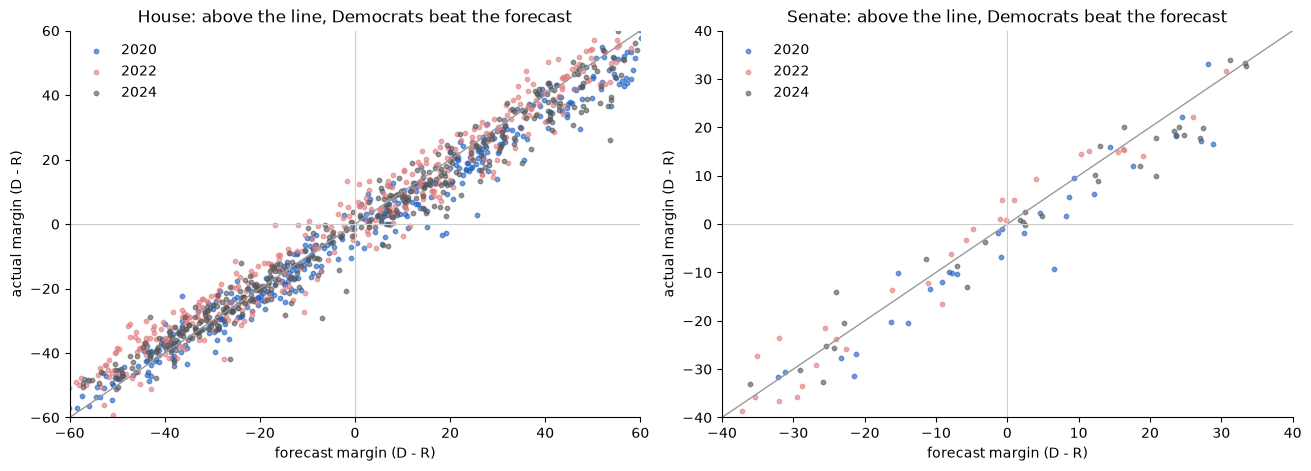

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained")
for ax, chamber in zip(axes, ["House", "Senate"]):
    rows = contested[(contested["chamber"] == chamber) & contested["actual"].notna()]
    for year, color in zip(YEARS, ["#1f5fbf", "#e07b7b", "#555"]):
        g = rows[rows["year"] == year]
        ax.scatter(g["margin"], g["actual"], s=10, alpha=0.6, color=color, label=str(year))
    lim = [-60, 60] if chamber == "House" else [-40, 40]
    ax.plot(lim, lim, color="#999", lw=1)
    ax.axhline(0, color="#ccc", lw=0.8)
    ax.axvline(0, color="#ccc", lw=0.8)
    ax.set(xlim=lim, ylim=lim, xlabel="forecast margin (D - R)", ylabel="actual margin (D - R)",
           title=f"{chamber}: above the line, Democrats beat the forecast")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 5. The candidate adjustments

These are the adjusted races, model beside adjusted, with what happened. The points are hindsight (see the top), so this shows how big they are next to these races' real errors, not whether they would have worked.

In [24]:
key = ["year", "race_id"]
both = races_model[[*key, "p_dem", "rating", "called_right"]].merge(
    races[[*key, "dem_candidate", "gop_candidate", "margin_model", "margin_adjustment", "margin", "actual", "p_dem",
           "rating", "called_right"]], on=key, suffixes=(" (model)", " (adjusted)"), validate="one_to_one")
both = BACKTEST_ADJUSTMENTS[key].merge(both, on=key).set_index(key)
both["model error"] = both["actual"] - both["margin_model"]
both["adjusted error"] = both["actual"] - both["margin"]
display(both.round(3))
display(Markdown(f"**Mean absolute error on these {len(both)} races:** model {both['model error'].abs().mean():.2f}, "
                 f"adjusted {both['adjusted error'].abs().mean():.2f} points"))
house_cards = pd.concat({"model": bt.scorecard(races_model), "adjusted": bt.scorecard(races)}, names=["run"])
house_cards.xs("House", level="chamber")[["called right", "misses", "Brier", "actual D wins", "called D wins",
                                          "not Safe: MAE", "not Safe: bias (D+)"]].round(3)

p_dem (model) rating (model)  called_right (model)         dem_candidate             gop_candidate  margin_model  margin_adjustment  margin  actual  p_dem (adjusted) rating (adjusted)  called_right (adjusted)  \
year race_id                                                                                                                                                                                                                     
2020 MN-05            1.000         Safe D                  True            Ilhan Omar              Lacy Johnson        53.375               -6.0  47.375  42.655             1.000            Safe D                     True   
     IA-02            0.779       Likely D                 False           Rita R Hart  Mariannette Miller-Meeks         4.825                2.5   7.325  -0.002             0.875          Likely D                    False   
     PA-01            0.366         Lean R                  True     Christina Finello       Brian K Fitzpatrick        -2.205               -5.0  -7.205 -13.116             0.129          Likely R                     True   
     UT-02            0.002         Safe R                  True           Kael Weston             Chris Stewart       -22.866               -2.5 -25.366 -23.390             0.001            Safe R                     True   
2022 MN-05            1.000         Safe D                  True            Ilhan Omar              Cicely Davis        46.568               -6.0  40.568  50.372             1.000            Safe D                     True   
     PA-01            0.041         Safe R                  True          Ashley Ehasz       Brian K Fitzpatrick       -11.089               -5.0 -16.089  -9.734             0.010            Safe R                     True   
     UT-02            0.001         Safe R                  True         Nick Mitchell             Chris Stewart       -30.445               -2.5 -32.945 -27.420             0.000            Safe R                     True   
2024 MN-05            1.000         Safe D                  True            Ilhan Omar            Dalia Al-Aqidi        51.944               -6.0  45.944  50.349             1.000            Safe D                     True   
     IA-02            0.052       Likely R                  True         Sarah Corkery             Ashley Hinson       -10.373                2.5  -7.873 -15.779             0.101          Likely R                     True   
     PA-01            0.118       Likely R                  True          Ashley Ehasz      Brian K. Fitzpatrick        -7.238               -5.0 -12.238 -12.806             0.031            Safe R                     True   
     AK-AL            0.618         Lean D                 False  Mary Sattler Peltola               Nick Begich         1.758                2.5   4.258  -1.047             0.762          Likely D                    False   

              model error  adjusted error  
year race_id                               
2020 MN-05        -10.720          -4.720  
     IA-02         -4.826          -7.326  
     PA-01        -10.911          -5.911  
     UT-02         -0.524           1.976  
2022 MN-05          3.803           9.803  
     PA-01          1.355           6.355  
     UT-02          3.026           5.526  
2024 MN-05         -1.594           4.406  
     IA-02         -5.406          -7.906  
     PA-01         -5.568          -0.568  
     AK-AL         -2.805          -5.305

**Mean absolute error on these 11 races:** model 4.59, adjusted 5.44 points

called right  misses  Brier  actual D wins  called D wins  not Safe: MAE  not Safe: bias (D+)
run      year                                                                                                 
model    2020           422.0    13.0  0.028          222.0          233.0          3.875               -1.946
         2022           418.0    17.0  0.029          213.0          212.0          4.820                0.833
         2024           428.0     7.0  0.013          215.0          218.0          3.803               -1.549
         pooled        1268.0    37.0  0.024          650.0          663.0          4.168               -0.899
adjusted 2020           422.0    13.0  0.028          222.0          233.0          3.842               -1.912
         2022           418.0    17.0  0.029          213.0          212.0          4.820                0.833
         2024           428.0     7.0  0.014          215.0          218.0          3.855               -1.565
         pooled        1268.0    37.0  0.024          650.0          663.0          4.173               -0.888

## 6. Same-party top-two races (no polls)

The 2026 top-two model, run on the 20 California and Washington races of 2020–2024:
- **Margins:** the June leader's predicted November margin over the runner-up, blending the primary (60) and fundraising (40), against the actual margin.
- **The pick:** the finalist with p ≥ 0.5.
- **The interval:** whether the result fell inside the 80% interval.

CA-53 2020 (Sara Jacobs) has no FEC record in either bulk file, so it uses the primary alone.

In [25]:
history = pd.read_csv(bt.TOP_TWO_HISTORY_PATH)
top_two = bt.top_two_backtest(history, weights_no_poll=TOP_TWO_WEIGHTS_NO_POLL,
                              points_per_log=house_forecast.TOP_TWO_POINTS_PER_LOG,
                              base_sd=house_forecast.TOP_TWO_BASE_SD, split_sd=house_forecast.TOP_TWO_SPLIT_SD,
                              nu=house_forecast.NU)
display(Markdown(
    f"**{int(top_two['called_right'].sum())} of {len(top_two)} called right**; mean p of the pick "
    f"{top_two[['p_leader', 'p_runner_up']].max(axis=1).mean():.2f}; margin MAE {top_two['error'].abs().mean():.1f} "
    f"points, bias (actual - predicted) {top_two['error'].mean():+.1f}; "
    f"{top_two['inside_80'].mean():.0%} inside the 80% interval"))
top_two[["year", "race_id", "leader", "runner_up", "margin_primary", "margin_fundraising", "weights", "mean", "sd",
         "p_leader", "predicted", "winner", "called_right", "actual_margin", "error", "inside_80"]].round(2)

**19 of 20 called right**; mean p of the pick 0.93; margin MAE 9.7 points, bias (actual - predicted) -6.4; 75% inside the 80% interval

,year,race_id,leader,runner_up,margin_primary,margin_fundraising,weights,mean,sd,p_leader,predicted,winner,called_right,actual_margin,error,inside_80
0,2020,CA-12,"Pelosi, Nancy","Buttar, Shahid",70.22,10.89,"primary 0.6, fundraising 0.4",46.49,8.90,1.00,"Pelosi, Nancy","Pelosi, Nancy",True,55.27,8.78,True
1,2020,CA-18,"Eshoo, Anna G.","Kumar, Rishi",58.04,3.40,"primary 0.6, fundraising 0.4",36.18,10.35,1.00,"Eshoo, Anna G.","Eshoo, Anna G.",True,26.34,-9.85,True
2,2020,CA-29,"Cardenas, Tony","Dueñas, Angélica Maria",43.52,8.68,"primary 0.6, fundraising 0.4",29.58,9.73,0.99,"Cardenas, Tony","Cardenas, Tony",True,13.22,-16.36,False
3,2020,CA-34,"Gomez, Jimmy","Kim, David",42.45,3.78,"primary 0.6, fundraising 0.4",26.98,11.37,0.99,"Gomez, Jimmy","Gomez, Jimmy",True,5.96,-21.02,False
4,2020,CA-38,"Sánchez, Linda T.","Tolar, Michael",55.41,54.49,"primary 0.6, fundraising 0.4",55.04,8.00,1.00,"Sánchez, Linda T.","Sánchez, Linda T.",True,48.68,-6.36,True
5,2020,CA-44,"Barragan, Nanette Diaz","Joya, Analilia",62.80,58.77,"primary 0.6, fundraising 0.4",61.19,10.37,1.00,"Barragan, Nanette Diaz","Barragan, Nanette Diaz",True,35.57,-25.62,False
6,2020,CA-53,"Jacobs, Sara","Gómez, Georgette",18.67,0.00,primary 1,18.67,17.24,0.89,"Jacobs, Sara","Jacobs, Sara",True,19.00,0.33,True
7,2020,WA-10,"Strickland, Marilyn","Doglio, Beth",14.62,0.31,"primary 0.6, fundraising 0.4",8.90,20.94,0.70,"Strickland, Marilyn","Strickland, Marilyn",True,16.23,7.33,True
8,2022,CA-15,"Mullin, Kevin","Canepa, David J.",26.07,0.53,"primary 0.6, fundraising 0.4",15.85,13.15,0.91,"Mullin, Kevin","Mullin, Kevin",True,10.92,-4.93,True
9,2022,CA-16,"Eshoo, Anna G.","Kumar, Rishi",50.83,3.20,"primary 0.6, fundraising 0.4",31.78,13.56,0.99,"Eshoo, Anna G.","Eshoo, Anna G.",True,15.54,-16.23,False


## 7. Kalshi, 2024

Kalshi listed 44 of the 2024 races. Each race's election-eve P(D) on Kalshi is its Democratic market's price at the close of Nov 4, normalized so the race sums to 1; the model's is the backtest's. Shown below:
- **Head to head:** Brier score and calls on the races both priced.
- **By price range:** races grouped by Kalshi's P(D), then by the model's, against how often Democrats won. This shows where each was over- or under-confident.
- **The strategy, replayed:** `run.py`'s toss-ups at quarter Kelly on a $1,000 bankroll, at the eve quotes. The bets are sized on the model's probabilities and scored on the actual results.
  - Fills are at the closing quote, with Kalshi's fee and no limit on depth (the historical book isn't known).

Kalshi's listed races are the competitive ones, so this is the hard end of the backtest.

In [26]:
kalshi_markets = bt.kalshi_markets_2024()
compare = bt.kalshi_compare(races, kalshi_markets)
brier = lambda p: ((p - compare["dem_won"]) ** 2).mean()
head_to_head = pd.DataFrame({
    "races": len(compare),
    "Brier: model": brier(compare["p_dem"]), "Brier: Kalshi": brier(compare["kalshi_p_dem"]),
    "called right: model": ((compare["p_dem"] > 0.5) == compare["dem_won"]).sum(),
    "called right: Kalshi": ((compare["kalshi_p_dem"] > 0.5) == compare["dem_won"]).sum(),
    "mean P(D): model": compare["p_dem"].mean(), "mean P(D): Kalshi": compare["kalshi_p_dem"].mean(),
    "D won": compare["dem_won"].sum()}, index=["2024"]).T
display(head_to_head.round(3))
display(Markdown("**By Kalshi's price range**"))
display(bt.bins(compare, "kalshi_p_dem").round(3))
display(Markdown("**By the model's probability range**"))
bt.bins(compare, "p_dem").round(3)

,2024
races,42.000
Brier: model,0.129
Brier: Kalshi,0.164
called right: model,35.000
called right: Kalshi,32.000
mean P(D): model,0.429
mean P(D): Kalshi,0.473
D won,16.000


**By Kalshi's price range**

,races,kalshi_p_dem,model_p_dem,dem_won
kalshi_p_dem,,,,
"(-0.001, 0.1]",8,0.040,0.002,0.000
"(0.1, 0.3]",4,0.198,0.206,0.000
"(0.3, 0.5]",6,0.413,0.294,0.167
"(0.5, 0.7]",12,0.582,0.603,0.583
"(0.7, 0.9]",11,0.759,0.655,0.636
"(0.9, 1.0]",1,0.940,0.991,1.000


**By the model's probability range**

,races,kalshi_p_dem,model_p_dem,dem_won
p_dem,,,,
"(-0.001, 0.1]",10,0.094,0.012,0.000
"(0.1, 0.3]",6,0.378,0.199,0.000
"(0.3, 0.5]",7,0.539,0.409,0.286
"(0.5, 0.7]",10,0.652,0.637,0.700
"(0.7, 0.9]",8,0.676,0.812,0.750
"(0.9, 1.0]",1,0.940,0.991,1.000


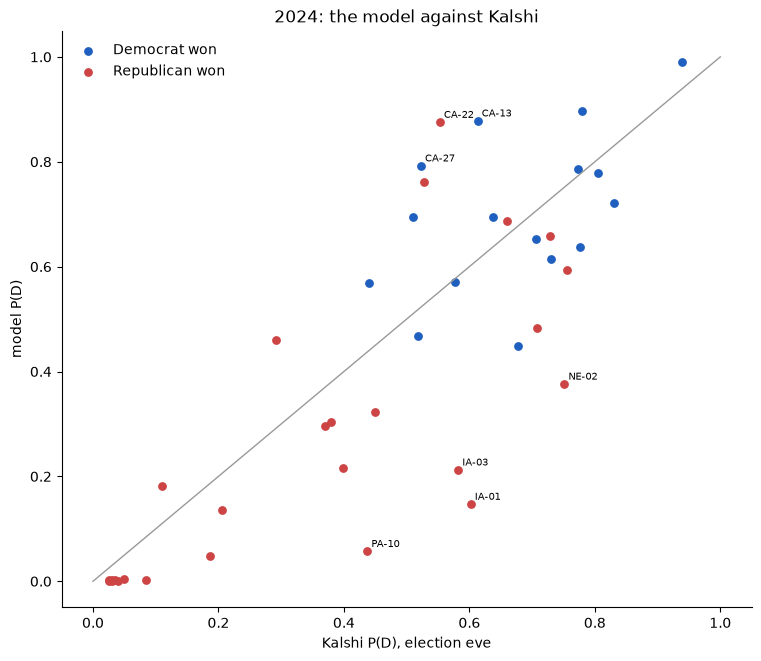

,race_id,chamber,dem_candidate,gop_candidate,rating,p_dem,kalshi_p_dem,model_minus_kalshi,winner_party,actual
1001,IA-01,House,Christina Bohannan,Mariannette Miller-Meeks,Likely R,0.147,0.602,-0.455,R,-0.193
1203,PA-10,House,Janelle Stelson,Scott Perry,Likely R,0.057,0.437,-0.380,R,-1.264
1119,NE-02,House,Tony Vargas,Don Bacon,Lean R,0.377,0.751,-0.375,R,-1.853
1003,IA-03,House,Lanon Baccam,Zachary Nunn,Likely R,0.213,0.582,-0.369,R,-3.834
1067,ME-02,House,Jared F. Golden,Austin Theriault,Toss-up,0.448,0.677,-0.229,D,0.691
1201,PA-08,House,Matt Cartwright,"Rob Bresnahan, Jr.",Toss-up,0.484,0.709,-0.225,R,-1.624
887,AZ-06,House,Kirsten Engel,Juan Ciscomani,Likely R,0.216,0.398,-0.182,R,-2.574
1200,PA-07,House,Susan Wild,Ryan E. Mackenzie,Toss-up,0.593,0.755,-0.162,R,-1.007
1386,MT-SEN,Senate,Jon Tester,Tim Sheehy,Safe R,0.048,0.186,-0.138,R,-7.278
1382,MI-SEN,Senate,Elissa Slotkin,Mike Rogers,Lean D,0.638,0.776,-0.138,D,0.352


In [27]:
fig, ax = plt.subplots(figsize=(7.5, 6.5), layout="constrained")
for won, color, label in [(True, "#1f5fbf", "Democrat won"), (False, "#c44", "Republican won")]:
    g = compare[compare["dem_won"] == won]
    ax.scatter(g["kalshi_p_dem"], g["p_dem"], color=color, s=28, label=label)
for _, r in compare[(compare["model_minus_kalshi"].abs() > 0.25)].iterrows():
    ax.annotate(r["race_id"], (r["kalshi_p_dem"], r["p_dem"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.plot([0, 1], [0, 1], color="#999", lw=1)
ax.set(xlabel="Kalshi P(D), election eve", ylabel="model P(D)", title="2024: the model against Kalshi")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
compare.sort_values("model_minus_kalshi")[["race_id", "chamber", "dem_candidate", "gop_candidate", "rating", "p_dem",
                                          "kalshi_p_dem", "model_minus_kalshi", "winner_party", "actual"]].round(3)

In [28]:
bets = bt.kalshi_strategy_2024(races, kalshi_markets, low=TOSSUP_LOW, high=TOSSUP_HIGH, bankroll=BANKROLL,
                               kelly_fraction=KELLY_FRACTION, min_edge=MIN_EDGE)
display(Markdown(f"**{len(bets)} bets, ${bets['stake'].sum():,.2f} staked:** expected profit "
                 f"${bets['expected_profit'].sum():,.2f} (the model's probabilities), realized "
                 f"**${bets['realized_profit'].sum():,.2f}**; {int((bets['realized_profit'] > 0).sum())} of {len(bets)} "
                 f"bets won"))
bets[["race_id", "candidate", "side", "price", "cost", "belief", "edge", "contracts", "stake", "expected_profit",
      "result", "realized_profit"]].round(3)

**13 bets, $996.91 staked:** expected profit $503.21 (the model's probabilities), realized **$384.09**; 8 of 13 bets won

,race_id,candidate,side,price,cost,belief,edge,contracts,stake,expected_profit,result,realized_profit
0,PA-10,Scott Perry,yes,0.57,0.587,0.943,0.355,292,171.450,103.797,yes,120.550
1,CA-22,David G. Valadao,no,0.56,0.577,0.876,0.299,243,140.271,72.536,yes,-140.271
2,IA-03,Lanon Baccam,no,0.43,0.447,0.787,0.340,273,122.074,92.839,no,150.926
3,CA-27,Mike Garcia,no,0.53,0.547,0.793,0.245,197,107.845,48.302,no,89.155
4,AK-AL,Mary Peltola,yes,0.53,0.547,0.762,0.214,172,94.159,36.888,no,-94.159
5,CA-45,Michelle Steel,no,0.52,0.537,0.695,0.158,126,67.721,19.858,no,58.279
6,ME-02,Austin Theriault,yes,0.33,0.345,0.552,0.207,182,62.877,37.619,no,-62.877
7,PA-08,Rob Bresnahan Jr.,yes,0.30,0.315,0.516,0.201,185,58.220,37.254,yes,126.780
8,CA-41,Will Rollins,no,0.56,0.577,0.678,0.100,81,46.757,8.131,no,34.243
9,MI-07,Tom Barrett,no,0.31,0.325,0.459,0.134,121,39.322,16.257,yes,-39.322


## Exports

`data/processed/forecast/`:
- `backtest_races.csv`: every race-year with its rating, probabilities, margins and result. The model run's `p_dem` and rating are beside the adjusted ones.
- `backtest_scorecard.csv`: section 1.
- `backtest_top_two.csv`: section 6.
- `backtest_kalshi_2024.csv`: section 7's races.
- `backtest_kalshi_2024_bets.csv`: the replayed bets.

In [29]:
OUT = ROOT / "data/processed/forecast"
export = races.merge(races_model[["year", "race_id", "p_dem", "rating"]], on=["year", "race_id"],
                     suffixes=("", " (model)"), validate="one_to_one")
outputs = {"backtest_races.csv": export, "backtest_scorecard.csv": bt.scorecard(races).reset_index(),
           "backtest_top_two.csv": top_two, "backtest_kalshi_2024.csv": compare, "backtest_kalshi_2024_bets.csv": bets}
for filename, frame in outputs.items():
    frame.round(6).to_csv(OUT / filename, index=False)
    print(f"-> {(OUT / filename).relative_to(ROOT)} ({len(frame)} rows)")

-> data/processed/forecast/backtest_races.csv (1405 rows)
-> data/processed/forecast/backtest_scorecard.csv (8 rows)
-> data/processed/forecast/backtest_top_two.csv (20 rows)
-> data/processed/forecast/backtest_kalshi_2024.csv (42 rows)
-> data/processed/forecast/backtest_kalshi_2024_bets.csv (13 rows)
